# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


Dataset Shape: (997, 9)

Rating Value Counts:
rating
5    580
4    188
3     94
1     87
2     48
Name: count, dtype: int64

First Few Rows:


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60



Top 20 Most Common Words:
[('nook', 1509), ('book', 913), ('one', 569), ('kindle', 561), ('screen', 496), ('like', 459), ('read', 454), ('work', 446), ('get', 424), ('great', 422), ('use', 420), ('tablet', 419), ('tv', 416), ('device', 381), ('would', 378), ('good', 330), ('bn', 321), ('time', 318), ('also', 317), ('well', 305)]

Top 20 Most Common Bigrams:
[(('barnes', 'noble'), 152), (('nook', 'color'), 127), (('battery', 'life'), 87), (('touch', 'screen'), 81), (('sd', 'card'), 80), (('nook', 'hd'), 74), (('work', 'great'), 63), (('nook', 'tablet'), 63), (('work', 'well'), 57), (('read', 'book'), 55), (('kindle', 'fire'), 55), (('wall', 'mount'), 51), (('simple', 'touch'), 44), (('android', 'tablet'), 39), (('customer', 'service'), 38), (('nook', 'simple'), 37), (('bn', 'store'), 35), (('easy', 'install'), 34), (('original', 'nook'), 34), (('ebook', 'reader'), 33)]


C:\Users\admin\AppData\Local\Temp\ipykernel_9880\3997065265.py:83: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words), palette='Blues_r')


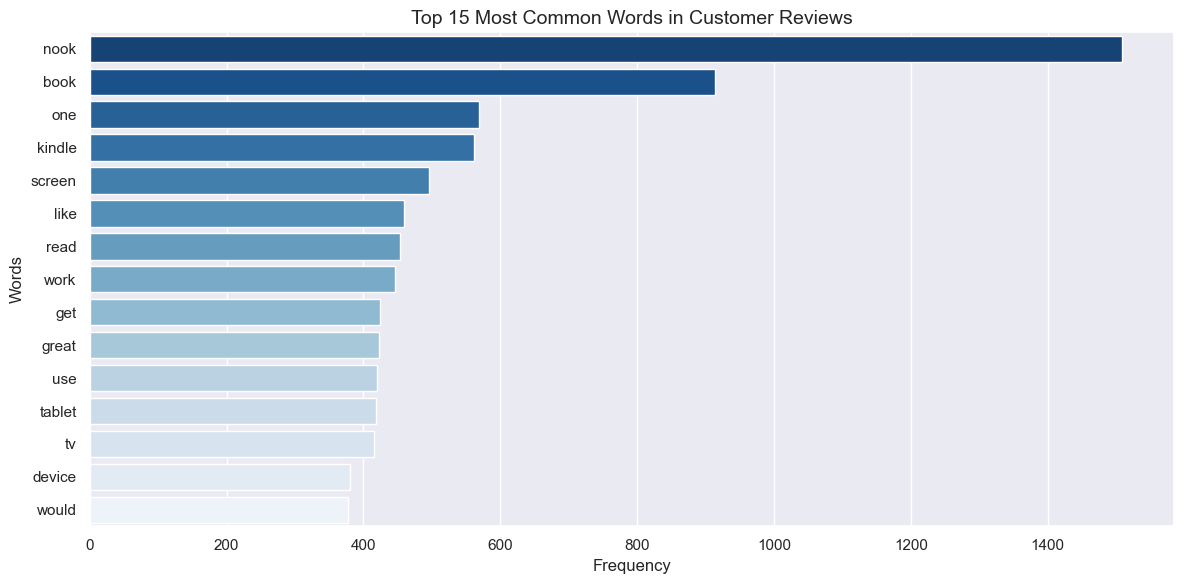

In [4]:
# ---------------------------------------------
# Part 1: NLP Starter Code
# ---------------------------------------------

# Import the libraries needed for data handling, plotting, text preprocessing, tokenization, and counting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Load the dataset ('amazon_reviews_lab.csv')
df = pd.read_csv('amazon_reviews_lab.csv')

# Explore the dataset (shape, value counts for rating column, and preview first few rows)
print("Dataset Shape:", df.shape)
print("\nRating Value Counts:")
print(df['rating'].value_counts())
print("\nFirst Few Rows:")
display(df.head())

# Create preprocessing tools: stopwords set and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# Write the preprocess_text function following all criteria:
def preprocess_text(text):
    if not isinstance(text, str):
        return []
    # 1. Converts text to lowercase
    text = text.lower()
    # 2. Removes URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # 3. Removes punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 4. Tokenizes the text
    tokens = word_tokenize(text)
    # 5. Keeps alphabetic tokens only
    tokens = [t for t in tokens if t.isalpha()]
    # 6. Removes stopwords
    tokens = [t for t in tokens if t not in stop_words]
    # 7. Lemmatizes the remaining tokens
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    # 8. Returns the cleaned tokens
    return tokens

# Apply your preprocessing function to the correct review text column ('review_text')
text_col = 'review_text' if 'review_text' in df.columns else df.columns[2]
df['processed_tokens'] = df[text_col].apply(preprocess_text)

# Combine all tokens into one list so you can compute word frequencies
all_tokens = [token for doc in df['processed_tokens'] for token in doc]

# Use Counter to identify the most common words
word_counts = Counter(all_tokens)
print("\nTop 20 Most Common Words:")
print(word_counts.most_common(20))

# Generate bigrams from the token list and identify the most common bigrams
all_bigrams = [bigram for doc in df['processed_tokens'] for bigram in ngrams(doc, 2)]
bigram_counts = Counter(all_bigrams)
print("\nTop 20 Most Common Bigrams:")
print(bigram_counts.most_common(20))

# Create visualization of the most common words
plt.figure(figsize=(12, 6))
common_words = word_counts.most_common(15)
words, counts = zip(*common_words)
sns.barplot(x=list(counts), y=list(words), palette='Blues_r')
plt.title('Top 15 Most Common Words in Customer Reviews', fontsize=14)
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.show()


## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


Earliest Timestamp: 2000-05-12 00:00:00
Latest Timestamp: 2014-07-17 00:00:00


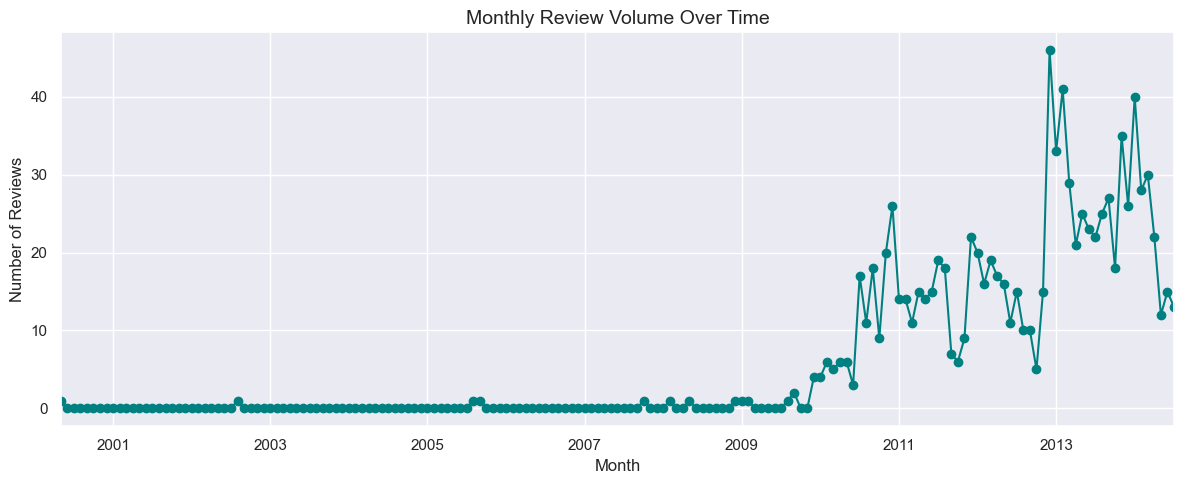

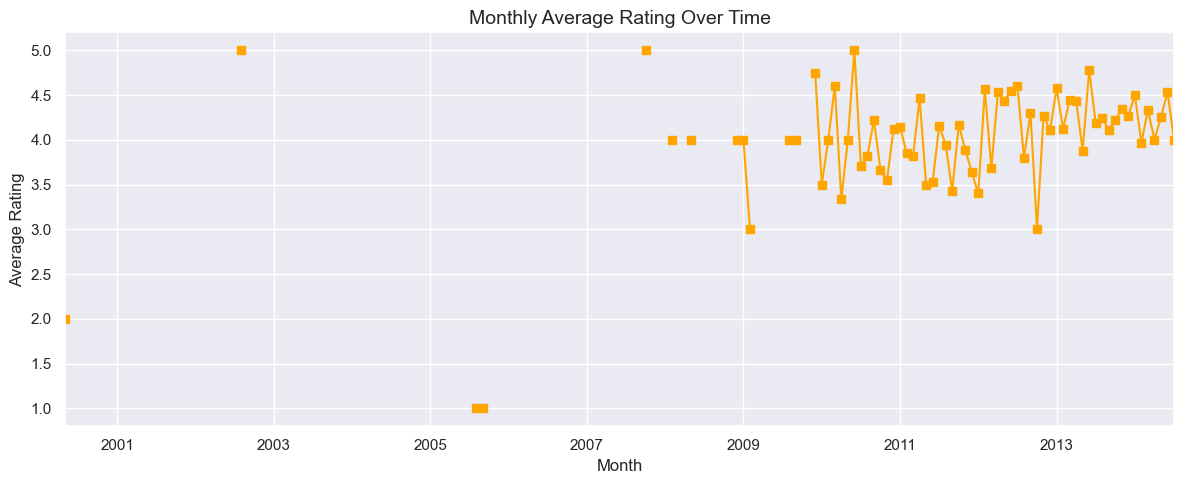

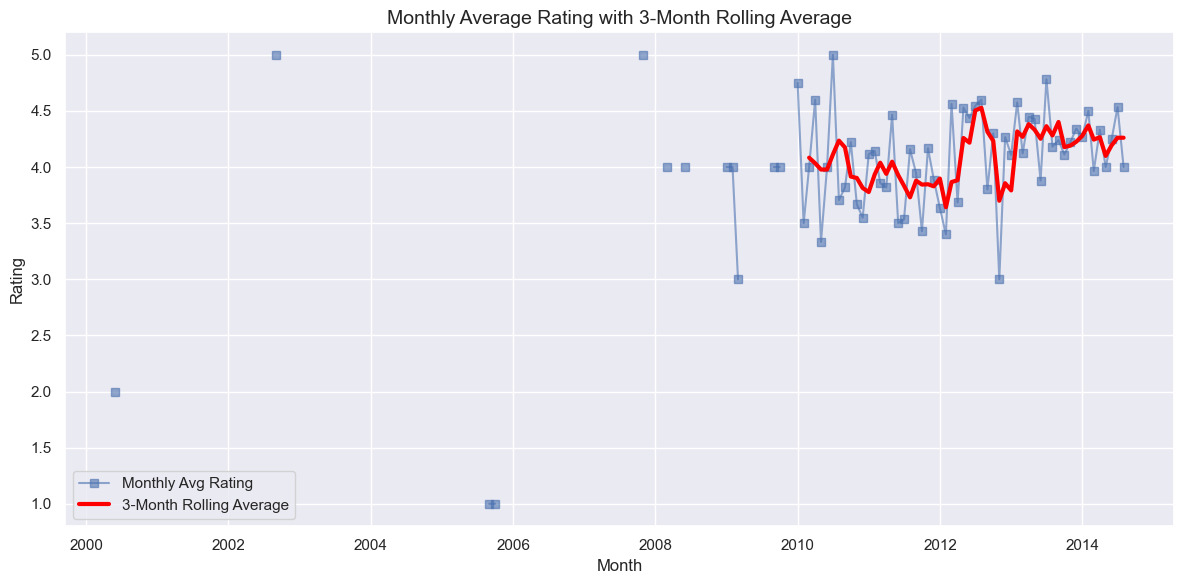

In [2]:
# ---------------------------------------------
# Part 2: Time Series Starter Code
# ---------------------------------------------

# TODO: Import the libraries you need.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

# TODO: Load the same review dataset.
if 'df' not in locals():
    df = pd.read_csv('amazon_reviews_lab.csv')

# TODO: Convert the timestamp column to datetime format.
date_col = 'timestamp' if 'timestamp' in df.columns else ('date' if 'date' in df.columns else df.columns[0])
df[date_col] = pd.to_datetime(df[date_col])

# TODO: Inspect the date range in the dataset.
print(f"Earliest Timestamp: {df[date_col].min()}")
print(f"Latest Timestamp: {df[date_col].max()}")

# Set timestamp as index for monthly resampling
df_ts = df.set_index(date_col)

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating
monthly_review_count = df_ts.resample('ME')['rating'].count()
monthly_avg_rating = df_ts.resample('ME')['rating'].mean()

# TODO: Plot monthly review volume over time.
plt.figure(figsize=(12, 5))
monthly_review_count.plot(kind='line', marker='o', color='teal')
plt.title('Monthly Review Volume Over Time', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True)
plt.tight_layout()
plt.show()

# TODO: Plot average monthly rating over time.
plt.figure(figsize=(12, 5))
monthly_avg_rating.plot(kind='line', marker='s', color='orange')
plt.title('Monthly Average Rating Over Time', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.grid(True)
plt.tight_layout()
plt.show()

# TODO: Compute a rolling average for the monthly average rating.
rolling_avg_rating = monthly_avg_rating.rolling(window=3).mean()

# TODO: Plot both original monthly average rating and rolling average on the same figure.
plt.figure(figsize=(12, 6))
plt.plot(monthly_avg_rating, label='Monthly Avg Rating', marker='s', alpha=0.6)
plt.plot(rolling_avg_rating, label='3-Month Rolling Average', linewidth=3, color='red')
plt.title('Monthly Average Rating with 3-Month Rolling Average', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Rating')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


Epoch 1/15
25/25 [==============================] - 2s 32ms/step - loss: 1.5266 - accuracy: 0.5220 - val_loss: 1.3896 - val_accuracy: 0.5800
Epoch 2/15
25/25 [==============================] - 0s 11ms/step - loss: 1.2187 - accuracy: 0.5822 - val_loss: 1.2237 - val_accuracy: 0.5800
Epoch 3/15
25/25 [==============================] - 0s 12ms/step - loss: 1.0531 - accuracy: 0.5822 - val_loss: 1.1479 - val_accuracy: 0.5800
Epoch 4/15
25/25 [==============================] - 0s 8ms/step - loss: 0.9004 - accuracy: 0.5872 - val_loss: 1.1369 - val_accuracy: 0.5800
Epoch 5/15
25/25 [==============================] - 0s 19ms/step - loss: 0.7041 - accuracy: 0.7026 - val_loss: 1.1257 - val_accuracy: 0.5750
Epoch 6/15
25/25 [==============================] - 0s 17ms/step - loss: 0.5084 - accuracy: 0.8256 - val_loss: 1.1911 - val_accuracy: 0.5700
Epoch 7/15
25/25 [==============================] - 0s 18ms/step - loss: 0.3404 - accuracy: 0.9122 - val_loss: 1.3083 - val_accuracy: 0.5650
Epoch 8/15
25/

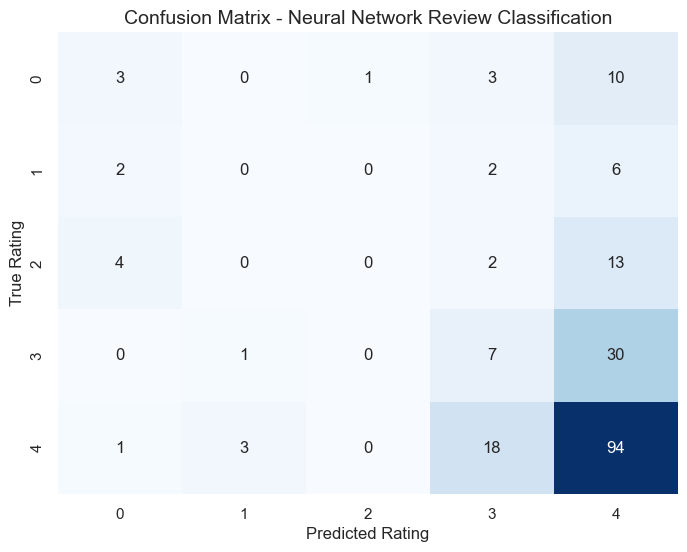

In [5]:
# ---------------------------------------------
# Part 3: Neural Networks Starter Code
# ---------------------------------------------

# Import libraries for data handling, splitting, vectorization, model building, and evaluation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

# Load the dataset
if 'df' not in locals():
    df = pd.read_csv('amazon_reviews_lab.csv')

# Define X as the review text column (handling missing values safely) and y as the rating column
text_column = 'review_text' if 'review_text' in df.columns else df.columns[2]
X = df[text_column].fillna("").astype(str)
y = df['rating']

# Adjust ratings from 1-5 to 0-4 for categorical crossentropy compatibility if necessary
if y.min() == 1:
    y = y - 1

# Vectorize the text using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_tfidf = vectorizer.fit_transform(X).toarray()

# Split the data into training and testing sets with stratify=y to preserve class balance
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)

# One-hot encode the target values for multi-class classification
num_classes = len(np.unique(y))
y_train_encoded = to_categorical(y_train, num_classes=num_classes)
y_test_encoded = to_categorical(y_test, num_classes=num_classes)

# Build a neural network model (Multi-Layer Perceptron)
model = tf.keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model and store the training history
history = model.fit(
    X_train, y_train_encoded,
    validation_data=(X_test, y_test_encoded),
    epochs=15,
    batch_size=32,
    verbose=1
)

# Evaluate the model on the test set
test_loss, test_acc = model.evaluate(X_test, y_test_encoded, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")

# Generate predictions on the test set
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create a classification report and confusion matrix to assess performance
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Neural Network Review Classification', fontsize=14)
plt.xlabel('Predicted Rating')
plt.ylabel('True Rating')
plt.show()